In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ppghr.data import ACTIVITY_NAMES, FS_ACC, FS_PPG, load_processed
from ppghr.windows import load_all_windows, make_windows

In [2]:
s1 = make_windows(load_processed("S1"))
for name, values in s1.items():
    print(f"{name:<9} {values.shape}")

ppg       (4603, 512)
acc       (4603, 256, 3)
hr        (4603,)
activity  (4603,)


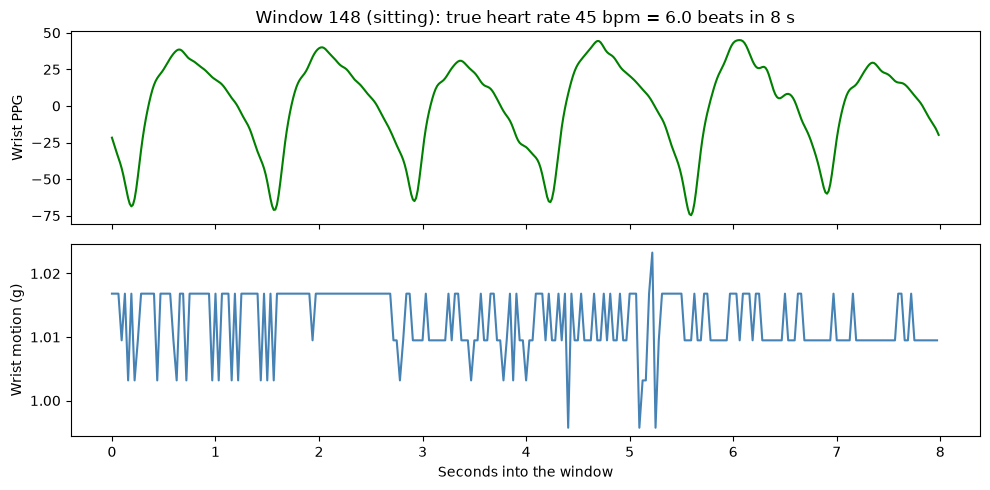

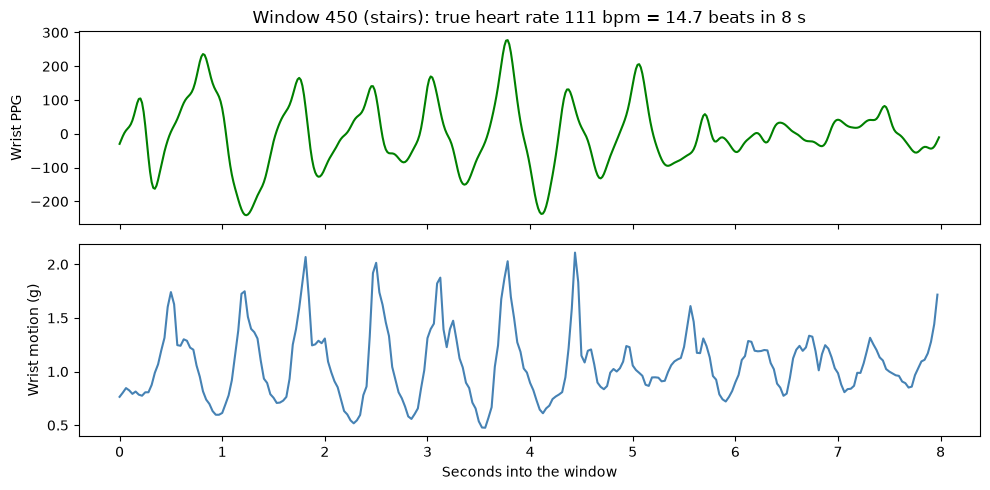

In [3]:
def plot_window(windows, i):
    ppg = windows["ppg"][i]
    motion = np.linalg.norm(windows["acc"][i], axis=1)
    hr = windows["hr"][i]
    activity = ACTIVITY_NAMES[int(windows["activity"][i])]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    ax1.plot(np.arange(len(ppg)) / FS_PPG, ppg, color="green")
    ax1.set_ylabel("Wrist PPG")
    ax1.set_title(f"Window {i} ({activity}): true heart rate {hr:.0f} bpm "
                  f"= {hr * 8 / 60:.1f} beats in 8 s")
    ax2.plot(np.arange(len(motion)) / FS_ACC, motion, color="steelblue")
    ax2.set_ylabel("Wrist motion (g)")
    ax2.set_xlabel("Seconds into the window")
    plt.tight_layout()
    plt.show()

plot_window(s1, 148)
plot_window(s1, 450)

In [4]:
data = load_all_windows()
for name, values in data.items():
    print(f"{name:<9} {values.shape}")

ppg       (64697, 512)
acc       (64697, 256, 3)
hr        (64697,)
activity  (64697,)
subject   (64697,)


In [5]:
table = pd.DataFrame({
    "subject": data["subject"],
    "activity": [ACTIVITY_NAMES[a] for a in data["activity"]],
    "hr": data["hr"],
})
table.groupby("activity")["hr"].agg(["count", "mean", "std"]).round(1).sort_values("mean")

,count,mean,std
activity,,,
sitting,4573,61.000000,12.900000
working,8501,76.400002,12.900000
lunch,13550,83.599998,14.500000
driving,6846,84.699997,15.000000
table soccer,2316,90.400002,18.200001
transition,17495,94.699997,21.200001
walking,4696,99.300003,16.400000
stairs,3242,118.800003,24.100000
cycling,3478,123.199997,23.700001


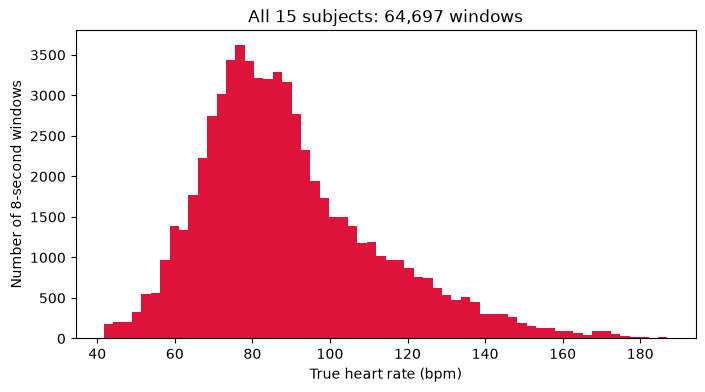

In [6]:
plt.figure(figsize=(8, 4))
plt.hist(data["hr"], bins=60, color="crimson")
plt.xlabel("True heart rate (bpm)")
plt.ylabel("Number of 8-second windows")
plt.title("All 15 subjects: 64,697 windows")
plt.show()